<a href="https://colab.research.google.com/github/GreeshmaBodapati/Plant_Leaf_Disease_Detection_MobileNetV2/blob/main/Plant_Leaf_Disease_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount("/content/drive")
import os
import zipfile
ZIP_PATH = "/content/drive/MyDrive/Dl Project/archive.zip"
EXTRACT_DIR = "/content/plant_dataset"
if not os.path.exists(ZIP_PATH):
    raise FileNotFoundError(
        f"Dataset ZIP not found at: {ZIP_PATH}\n"
        "Update ZIP_PATH to the location of archive.zip in Google Drive."
    )
# Extract only if the expected dataset directory is not already available.
EXPECTED_DATA_DIR = os.path.join(EXTRACT_DIR, "plantvillage dataset", "color")
if not os.path.isdir(EXPECTED_DATA_DIR):
    os.makedirs(EXTRACT_DIR, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(EXTRACT_DIR)
print("Dataset directory exists:", os.path.isdir(EXPECTED_DATA_DIR))
print("Dataset path:", EXPECTED_DATA_DIR)

Mounted at /content/drive
Dataset directory exists: True
Dataset path: /content/plant_dataset/plantvillage dataset/color


In [2]:
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
SEED = 42
IMG_SIZE = 160
BATCH_SIZE = 32
EPOCHS = 5
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
DATASET_PATH = "/content/plant_dataset/plantvillage dataset/color"
if not os.path.isdir(DATASET_PATH):
    raise FileNotFoundError(
        f"Could not find {DATASET_PATH}. Check the ZIP's folder structure and update DATASET_PATH."
    )
class_names = sorted([
    name for name in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, name))
])
class_to_index = {name: i for i, name in enumerate(class_names)}
all_paths = []
all_labels = []
valid_extensions = (".jpg", ".jpeg", ".png", ".bmp")
for class_name in class_names:
    folder = os.path.join(DATASET_PATH, class_name)
    label = class_to_index[class_name]
    for filename in os.listdir(folder):
        if filename.lower().endswith(valid_extensions):
            all_paths.append(os.path.join(folder, filename))
            all_labels.append(label)
all_paths = np.array(all_paths)
all_labels = np.array(all_labels, dtype=np.int32)
print("Total images:", len(all_paths))
print("Number of classes:", len(class_names))
print("\nClasses:")
for i, name in enumerate(class_names):
    print(i, name)
assert len(class_names) == 38, f"Expected 38 classes, found {len(class_names)}"
assert len(all_paths) > 0, "No images found. Check DATASET_PATH."

Total images: 54305
Number of classes: 38

Classes:
0 Apple___Apple_scab
1 Apple___Black_rot
2 Apple___Cedar_apple_rust
3 Apple___healthy
4 Blueberry___healthy
5 Cherry_(including_sour)___Powdery_mildew
6 Cherry_(including_sour)___healthy
7 Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
8 Corn_(maize)___Common_rust_
9 Corn_(maize)___Northern_Leaf_Blight
10 Corn_(maize)___healthy
11 Grape___Black_rot
12 Grape___Esca_(Black_Measles)
13 Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
14 Grape___healthy
15 Orange___Haunglongbing_(Citrus_greening)
16 Peach___Bacterial_spot
17 Peach___healthy
18 Pepper,_bell___Bacterial_spot
19 Pepper,_bell___healthy
20 Potato___Early_blight
21 Potato___Late_blight
22 Potato___healthy
23 Raspberry___healthy
24 Soybean___healthy
25 Squash___Powdery_mildew
26 Strawberry___Leaf_scorch
27 Strawberry___healthy
28 Tomato___Bacterial_spot
29 Tomato___Early_blight
30 Tomato___Late_blight
31 Tomato___Leaf_Mold
32 Tomato___Septoria_leaf_spot
33 Tomato___Spider_mites Tw

In [4]:
# First hold out 15% for the final test set.
trainval_paths, test_paths, trainval_labels, test_labels = train_test_split(
    all_paths, all_labels,
    test_size=0.15,
    random_state=SEED,
    stratify=all_labels
)
# Validation should be 15% of the full dataset.
val_fraction_of_trainval = 0.15 / 0.85
train_paths, val_paths, train_labels, val_labels = train_test_split(
    trainval_paths, trainval_labels,
    test_size=val_fraction_of_trainval,
    random_state=SEED,
    stratify=trainval_labels
)
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Testing images:", len(test_paths))
print("Total:", len(train_paths) + len(val_paths) + len(test_paths))
# Explicitly verify that paths do not overlap.
assert set(train_paths).isdisjoint(set(val_paths))
assert set(train_paths).isdisjoint(set(test_paths))
assert set(val_paths).isdisjoint(set(test_paths))
print("Verified: no overlapping image paths.")

Training images: 38013
Validation images: 8146
Testing images: 8146
Total: 54305
Verified: no overlapping image paths.


In [5]:
AUTOTUNE = tf.data.AUTOTUNE
def load_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(
        image_bytes, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)
    return image, label
def create_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(
            buffer_size=min(len(paths), 10000),
            seed=SEED,
            reshuffle_each_iteration=True
        )
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)
    return ds
train_ds = create_dataset(train_paths, train_labels, training=True)
val_ds = create_dataset(val_paths, val_labels)
test_ds = create_dataset(test_paths, test_labels)
print("Training, validation, and test datasets are ready.")

Training, validation, and test datasets are ready.


In [6]:
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False
inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = layers.Rescaling(1.0 / 127.5, offset=-1)(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)
model = models.Model(inputs, outputs)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [7]:
MODEL_PATH = "/content/plant_disease_mobilenetv2_best.keras"
callbacks = [
    EarlyStopping(
        monitor="val_accuracy",
        patience=2,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        MODEL_PATH,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.7477 - loss: 0.9692
Epoch 1: val_accuracy improved from None to 0.94378, saving model to /content/plant_disease_mobilenetv2_best.keras

Epoch 1: finished saving model to /content/plant_disease_mobilenetv2_best.keras
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 73s 51ms/step - accuracy: 0.8582 - loss: 0.4984 - val_accuracy: 0.9438 - val_loss: 0.1878
Epoch 2/5
1186/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9356 - loss: 0.2036
Epoch 2: val_accuracy improved from 0.94378 to 0.95200, saving model to /content/plant_disease_mobilenetv2_best.keras

Epoch 2: finished saving model to /content/plant_disease_mobilenetv2_best.keras
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 40s 34ms/step - accuracy: 0.9378 - loss: 0.1947 - val_accuracy: 0.9520 - val_loss: 0.1558
Epoch 3/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9473 - loss: 0.1575
Epoch 3: val_accuracy did not improve from 0.95200
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 38s 32ms/step - a

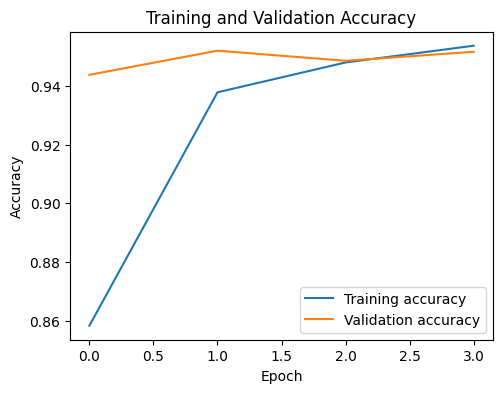

In [9]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

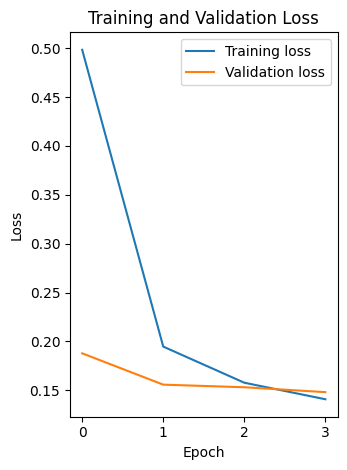

In [10]:
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
# Load the best checkpoint selected using validation accuracy.
model = tf.keras.models.load_model(MODEL_PATH)
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"Independent test accuracy: {test_accuracy * 100:.2f}%")
print(f"Test loss: {test_loss:.4f}")

255/255 ━━━━━━━━━━━━━━━━━━━━ 15s 35ms/step - accuracy: 0.9509 - loss: 0.1553
Independent test accuracy: 95.09%
Test loss: 0.1553


In [12]:
y_true = np.concatenate([labels.numpy() for _, labels in test_ds])
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

255/255 ━━━━━━━━━━━━━━━━━━━━ 25s 74ms/step
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     0.8750    0.8936    0.8842        94
                                 Apple___Black_rot     0.8532    1.0000    0.9208        93
                          Apple___Cedar_apple_rust     1.0000    0.8049    0.8919        41
                                   Apple___healthy     0.9676    0.9676    0.9676       247
                               Blueberry___healthy     0.9867    0.9911    0.9889       225
          Cherry_(including_sour)___Powdery_mildew     1.0000    0.9810    0.9904       158
                 Cherry_(including_sour)___healthy     0.9921    0.9766    0.9843       128
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.8784    0.8442    0.8609        77
                       Corn_(maize)___Common_rust_     0.9890    1.0000    0.9944       179
               Corn_(maize)___Northe

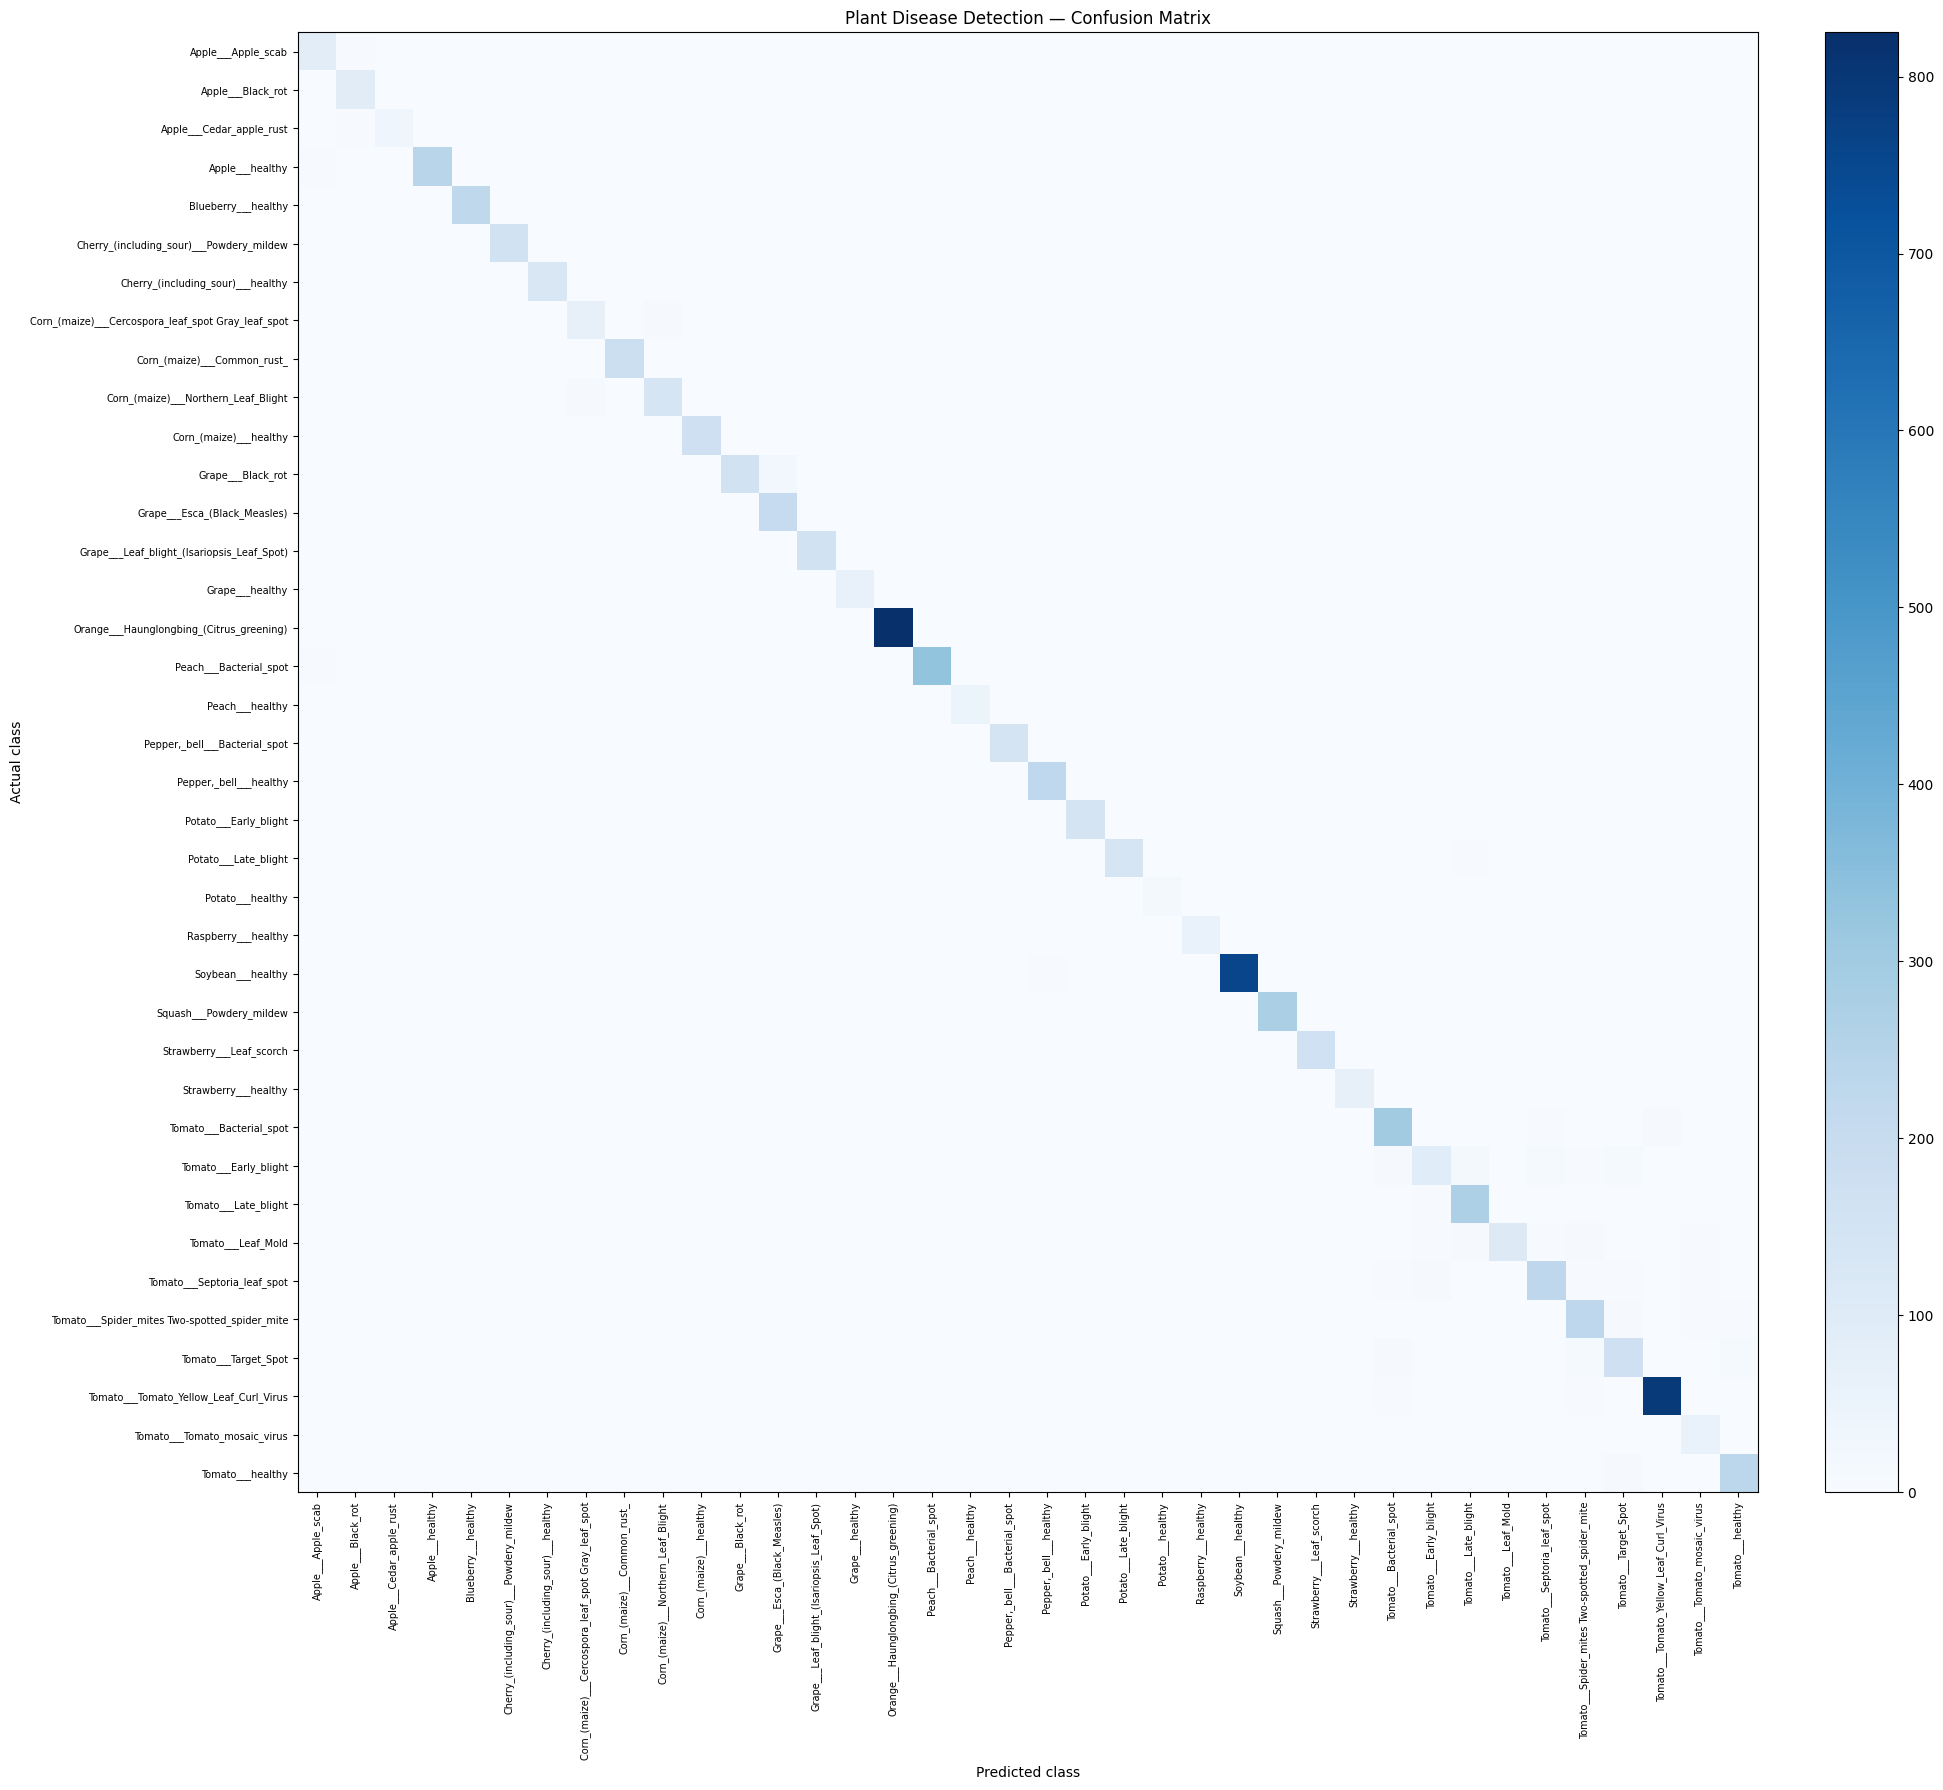

In [13]:
cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_names)))
fig, ax = plt.subplots(figsize=(20, 18))
im = ax.imshow(cm, interpolation="nearest", cmap="Blues")
ax.set_title("Plant Disease Detection — Confusion Matrix")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
tick_marks = np.arange(len(class_names))
ax.set_xticks(tick_marks)
ax.set_yticks(tick_marks)
ax.set_xticklabels(class_names, rotation=90, fontsize=7)
ax.set_yticklabels(class_names, fontsize=7)
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")
plt.tight_layout()
plt.show()

In [14]:
import json
CLASS_NAMES_PATH = "/content/plant_disease_classes.json"
RESULTS_PATH = "/content/plant_disease_results.json"
FINAL_MODEL_PATH = "/content/plant_disease_mobilenetv2_final.keras"
model.save(FINAL_MODEL_PATH)
with open(CLASS_NAMES_PATH, "w") as f:
    json.dump(class_names, f, indent=2)
report_dict = classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)
results = {
    "model": "MobileNetV2",
    "image_size": IMG_SIZE,
    "number_of_classes": len(class_names),
    "train_images": int(len(train_paths)),
    "validation_images": int(len(val_paths)),
    "test_images": int(len(test_paths)),
    "test_accuracy": float(test_accuracy),
    "test_loss": float(test_loss),
    "classification_report": report_dict
}
with open(RESULTS_PATH, "w") as f:
    json.dump(results, f, indent=2)
print("Saved:")
print(FINAL_MODEL_PATH)
print(CLASS_NAMES_PATH)
print(RESULTS_PATH)

Saved:
/content/plant_disease_mobilenetv2_final.keras
/content/plant_disease_classes.json
/content/plant_disease_results.json


Saving 085625a8-236d-4f71-bd40-78e3e4f24eb0___JR_FrgE.S 2732.JPG to 085625a8-236d-4f71-bd40-78e3e4f24eb0___JR_FrgE.S 2732.JPG


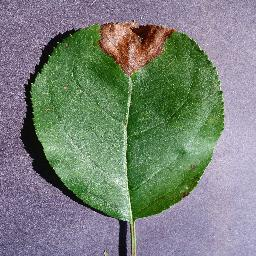

Top predictions:
1. Apple___Black_rot: 99.99%
2. Potato___Late_blight: 0.00%
3. Orange___Haunglongbing_(Citrus_greening): 0.00%
4. Apple___healthy: 0.00%
5. Strawberry___Leaf_scorch: 0.00%

Note: Model confidence is not a guarantee of a correct diagnosis.


In [15]:
from google.colab import files
from PIL import Image
from IPython.display import display
uploaded = files.upload()
if not uploaded:
    raise ValueError("No image was uploaded.")
image_path = next(iter(uploaded))
original_image = Image.open(image_path).convert("RGB")
display(original_image)
resized = original_image.resize((IMG_SIZE, IMG_SIZE))
image_array = np.asarray(resized, dtype=np.float32)
image_array = np.expand_dims(image_array, axis=0)
probabilities = model.predict(image_array, verbose=0)[0]
top_indices = np.argsort(probabilities)[-5:][::-1]
print("Top predictions:")
for rank, idx in enumerate(top_indices, start=1):
    print(f"{rank}. {class_names[idx]}: {probabilities[idx] * 100:.2f}%")
print("\nNote: Model confidence is not a guarantee of a correct diagnosis.")

In [16]:
from google.colab import files
files.download("/content/plant_disease_mobilenetv2_final.keras")
files.download("/content/plant_disease_classes.json")
files.download("/content/plant_disease_results.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>